# E-commerce Email A/B Test Analysis

## Summary

- **Both emails work.** Compared with sending nothing, the men's email raised the visit rate from 10.6% to 18.3%,
  roughly doubled conversion (0.57% → 1.25%) and added about $0.77 of spend per customer over two weeks.
  The women's email had about half that effect.
- **The gain comes from more buyers, not bigger orders.** Average order value was about the same in every group.
- **The men's email works for everyone; the women's email works mainly on women's buyers.** For customers who had bought only men's
  products, the women's email barely moved visits (+1 pt vs +7 pts for the men's email). For women's-only buyers,
  both emails performed about equally.
- **Recommendation:** use the men's email as the default. The women's email can be kept for customers who buy only
  women's products (no measurable difference in results), but should not be sent to men's-only buyers.

**Data:** Kevin Hillstrom, *MineThatData E-Mail Analytics and Data Mining Challenge* (2008).
64,000 customers who purchased within the last 12 months were randomly split into three groups:

| Group | What they received |
|---|---|
| Mens E-Mail | An email featuring men's merchandise |
| Womens E-Mail | An email featuring women's merchandise |
| No E-Mail | Nothing (control group) |

Site visits, purchases and spend were then tracked for two weeks.

**Questions**
1. Do the emails increase visits, purchases and spend?
2. Which customers respond to which email?
3. Who should receive which email in future campaigns?

## 1. Setup

Import libraries and locate the data. The notebook searches upward from its own folder until it finds the
repository root (the folder containing `.git`), so the paths work no matter where the notebook sits in the repo
or whose computer it runs on.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

pd.set_option("display.float_format", "{:.4f}".format)

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())
DATA_PATH = REPO_ROOT / "data" / "data.csv"
OUTPUT_DIR = REPO_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

df = pd.read_csv(DATA_PATH)
df.head()

,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.4400,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0000
1,6,3) $200 - $350,329.0800,1,1,Rural,1,Web,No E-Mail,0,0,0.0000
2,7,2) $100 - $200,180.6500,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0000
3,9,5) $500 - $750,675.8300,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0000
4,2,1) $0 - $100,45.3400,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0000


## 2. Data check

Before comparing groups, confirm that the data is complete, internally consistent, and that the
experiment was properly randomized.

### 2.1 First look
Shape, data types, missing values and duplicates.

In [2]:
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.dtypes

Shape: (64000, 12)
Missing values: 0
Duplicate rows: 6562


recency              int64
history_segment        str
history            float64
mens                 int64
womens               int64
zip_code               str
newbie               int64
channel                str
segment                str
visit                int64
conversion           int64
spend              float64
dtype: object

There are no missing values. The duplicate rows are not treated as errors: the dataset has no customer ID,
and many customers share the same simple profile (e.g. $29.99 spend history, same region and channel),
so identical rows are expected. They are kept.

### 2.2 Fix the `zip_code` typo
The raw data spells *Suburban* as *Surburban*.

In [3]:
df["zip_code"] = df["zip_code"].replace({"Surburban": "Suburban"})
df["zip_code"].value_counts()

zip_code
Suburban    28776
Urban       25661
Rural        9563
Name: count, dtype: int64

### 2.3 Split `history_segment` into numeric columns
`history_segment` is a text label such as `3) $200 - $350`. It is split into three columns:

| New column | Meaning | Example |
|---|---|---|
| `hist_seg_id` | Bucket number 1–7 | `3` |
| `hist_min` | Lower bound of the bucket ($) | `200` |
| `hist_max` | Upper bound of the bucket ($) | `350` |

The top bucket, `7) $1,000 +`, has no upper bound, so its `hist_max` is left empty (`NaN`) rather than filled
with an invented number.

The regular expression reads: *a digit* → `) $` → *the lower amount* → either `- $` *and the upper amount*, or `+`.

In [4]:
pattern = r"^(?P<id>\d)\)\s*\$(?P<min>[\d,]+)\s*(?:-\s*\$(?P<max>[\d,]+)|\+)$"
parts = df["history_segment"].str.extract(pattern)

# Stop if any label did not match the pattern
assert parts["id"].notna().all(), df.loc[parts["id"].isna(), "history_segment"].unique()

df["hist_seg_id"] = parts["id"].astype(int)
df["hist_min"] = parts["min"].str.replace(",", "").astype(float)
df["hist_max"] = parts["max"].str.replace(",", "").astype(float)  # NaN for "$1,000 +"

(df.groupby("hist_seg_id")
   .agg(label=("history_segment", "first"),
        hist_min=("hist_min", "first"),
        hist_max=("hist_max", "first"),
        customers=("hist_seg_id", "size")))

,label,hist_min,hist_max,customers
hist_seg_id,,,,
1,1) $0 - $100,0.0000,100.0000,22970
2,2) $100 - $200,100.0000,200.0000,14254
3,3) $200 - $350,200.0000,350.0000,12289
4,4) $350 - $500,350.0000,500.0000,6409
5,5) $500 - $750,500.0000,750.0000,4911
6,"6) $750 - $1,000",750.0000,1000.0000,1859
7,"7) $1,000 +",1000.0000,NaN,1308


Check that each customer's exact `history` value actually falls inside its bucket. For the open-ended top
bucket, the upper bound is treated as infinity.

In [5]:
upper = df["hist_max"].fillna(np.inf)
outside = ~df["history"].between(df["hist_min"], upper)
print("Customers outside their bucket:", outside.sum())

Customers outside their bucket: 0


Every customer falls inside their bucket, so the split is correct. It also shows that `history_segment`
adds no information beyond `history`: it is simply `history` grouped into ranges. The bucket number is still
useful later for segment analysis.

### 2.4 Logical consistency of the outcomes
The three outcomes form a funnel: **visit → conversion → spend**. A customer cannot buy without visiting,
and cannot spend without buying. Every customer should also have bought at least one category in the past year.

In [6]:
checks = {
    "Bought neither mens nor womens":   ((df["mens"] == 0) & (df["womens"] == 0)).sum(),
    "Converted without visiting":       ((df["conversion"] == 1) & (df["visit"] == 0)).sum(),
    "Spent without converting":         ((df["spend"] > 0) & (df["conversion"] == 0)).sum(),
}
pd.Series(checks, name="rows (should be 0)")

Bought neither mens nor womens    0
Converted without visiting        0
Spent without converting          0
Name: rows (should be 0), dtype: int64

### 2.5 Data dictionary
Columns fall into three roles:
- **Pre-treatment**: measured *before* the email was sent. Safe to use for describing and segmenting customers.
- **Treatment**: which email the customer received.
- **Outcome**: measured *after* the email. These are what we compare between groups and must never be used to
  describe customers in advance.

In [7]:
descriptions = {
    "recency":         ("Pre-treatment", "Months since last purchase"),
    "history_segment": ("Pre-treatment", "Past-year spend bucket (raw text)"),
    "history":         ("Pre-treatment", "Past-year spend ($)"),
    "mens":            ("Pre-treatment", "1 = bought men's merchandise in past year"),
    "womens":          ("Pre-treatment", "1 = bought women's merchandise in past year"),
    "zip_code":        ("Pre-treatment", "Urban / Suburban / Rural"),
    "newbie":          ("Pre-treatment", "1 = new customer in past 12 months"),
    "channel":         ("Pre-treatment", "Channels purchased from in past year: Phone / Web / Multichannel"),
    "segment":         ("Treatment",     "Mens E-Mail / Womens E-Mail / No E-Mail"),
    "visit":           ("Outcome",       "1 = visited the site within 2 weeks"),
    "conversion":      ("Outcome",       "1 = purchased within 2 weeks"),
    "spend":           ("Outcome",       "Amount spent within 2 weeks ($)"),
    "hist_seg_id":     ("Derived",       "History bucket number 1–7"),
    "hist_min":        ("Derived",       "Bucket lower bound ($)"),
    "hist_max":        ("Derived",       "Bucket upper bound ($); empty = open-ended"),
}

dictionary = pd.DataFrame({
    "column":      df.columns,
    "role":        [descriptions[c][0] for c in df.columns],
    "dtype":       df.dtypes.astype(str).values,
    "n_unique":    df.nunique().values,
    "min":         [df[c].min() if pd.api.types.is_numeric_dtype(df[c]) else "" for c in df.columns],
    "max":         [df[c].max() if pd.api.types.is_numeric_dtype(df[c]) else "" for c in df.columns],
    "description": [descriptions[c][1] for c in df.columns],
})
dictionary.to_csv(OUTPUT_DIR / "data_dictionary.csv", index=False)
dictionary

,column,role,dtype,n_unique,min,max,description
0,recency,Pre-treatment,int64,12,1,12,Months since last purchase
1,history_segment,Pre-treatment,str,7,,,Past-year spend bucket (raw text)
2,history,Pre-treatment,float64,34833,29.9900,3345.9300,Past-year spend ($)
3,mens,Pre-treatment,int64,2,0,1,1 = bought men's merchandise in past year
4,womens,Pre-treatment,int64,2,0,1,1 = bought women's merchandise in past year
5,zip_code,Pre-treatment,str,3,,,Urban / Suburban / Rural
6,newbie,Pre-treatment,int64,2,0,1,1 = new customer in past 12 months
7,channel,Pre-treatment,str,3,,,Channels purchased from in past year: Phone / ...
8,segment,Treatment,str,3,,,Mens E-Mail / Womens E-Mail / No E-Mail
9,visit,Outcome,int64,2,0,1,1 = visited the site within 2 weeks


### 2.6 Randomization check
The comparison between groups is only fair if the three groups were alike *before* the email was sent.
If, for example, the Mens E-Mail group had happened to contain more big spenders, any difference in
outcomes could come from that rather than from the email.

Three checks on the pre-treatment variables:
1. **Group sizes**: should be roughly equal (about 21,300 each).
2. **Group averages**: should be nearly identical.
3. **Statistical tests**: ANOVA for numeric columns and chi-square for categorical columns. A large p-value
   (> 0.05) means no evidence that the groups differ.

In [8]:
numeric_pre = ["recency", "history", "mens", "womens", "newbie"]
categorical_pre = ["zip_code", "channel", "hist_seg_id"]

df["segment"].value_counts()

segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64

In [9]:
df.groupby("segment")[numeric_pre].mean()

,recency,history,mens,womens,newbie
segment,,,,,
Mens E-Mail,5.7736,242.8359,0.5509,0.5514,0.5015
No E-Mail,5.7497,240.8827,0.5532,0.5476,0.5020
Womens E-Mail,5.7678,242.5366,0.5489,0.5501,0.5032


The **standardized mean difference (SMD)** expresses the gap between a treatment group and the control group in
units of standard deviation, so columns on different scales (months vs. dollars) can be compared.

$$SMD = \frac{\text{mean}_{treatment} - \text{mean}_{control}}{\sqrt{(\text{var}_{treatment} + \text{var}_{control})\,/\,2}}$$

A common rule of thumb: |SMD| < 0.1 means the groups are balanced.

In [10]:
def smd(treat, control):
    pooled_sd = np.sqrt((treat.var() + control.var()) / 2)
    return (treat.mean() - control.mean()) / pooled_sd

control = df[df["segment"] == "No E-Mail"]
smd_table = pd.DataFrame({
    grp: {col: smd(df.loc[df["segment"] == grp, col], control[col]) for col in numeric_pre}
    for grp in ["Mens E-Mail", "Womens E-Mail"]
})
smd_table

,Mens E-Mail,Womens E-Mail
recency,0.0068,0.0052
history,0.0076,0.0065
mens,-0.0046,-0.0086
womens,0.0076,0.0049
newbie,-0.0009,0.0026


In [11]:
balance_tests = []

for col in numeric_pre:
    groups = [g[col] for _, g in df.groupby("segment")]
    balance_tests.append((col, "ANOVA", stats.f_oneway(*groups).pvalue))

for col in categorical_pre:
    table = pd.crosstab(df[col], df["segment"])
    balance_tests.append((col, "Chi-square", stats.chi2_contingency(table)[1]))

pd.DataFrame(balance_tests, columns=["variable", "test", "p_value"])

,variable,test,p_value
0,recency,ANOVA,0.7631
1,history,ANOVA,0.6980
2,mens,ANOVA,0.6717
3,womens,ANOVA,0.7289
4,newbie,ANOVA,0.9339
5,zip_code,Chi-square,0.5795
6,channel,Chi-square,0.4580
7,hist_seg_id,Chi-square,0.3580


**Result:** the three groups are almost the same size, their averages are nearly identical, every SMD is far
below 0.1, and no test finds a significant difference. The randomization worked, so differences in outcomes
between the groups can be attributed to the emails.

### 2.7 Save the cleaned data

In [12]:
df.to_csv(REPO_ROOT / "data" / "data_clean.csv", index=False)
print("Saved:", REPO_ROOT / "data" / "data_clean.csv")

Saved: /tmp/repo/data/data_clean.csv


## 3. Did the emails work?

Each email group is compared with the No E-Mail control group on three outcomes:

| Metric | Type | Test used |
|---|---|---|
| Visit rate | yes/no (proportion) | Two-proportion z-test |
| Conversion rate | yes/no (proportion) | Two-proportion z-test |
| Spend per customer | dollars, mostly $0 | Bootstrap confidence interval |

Effects are reported as **absolute lift** (percentage points), **relative lift** (%), and a **95% confidence
interval**, not just a p-value: the interval shows how large the effect plausibly is, not only whether it exists.

### 3.1 Results by group

In [13]:
group_summary = df.groupby("segment").agg(
    customers=("visit", "size"),
    visits=("visit", "sum"),
    visit_rate=("visit", "mean"),
    conversions=("conversion", "sum"),
    conversion_rate=("conversion", "mean"),
    spend_per_customer=("spend", "mean"),
)
group_summary

,customers,visits,visit_rate,conversions,conversion_rate,spend_per_customer
segment,,,,,,
Mens E-Mail,21307,3894,0.1828,267,0.0125,1.4226
No E-Mail,21306,2262,0.1062,122,0.0057,0.6528
Womens E-Mail,21387,3238,0.1514,189,0.0088,1.0772


Both emails beat no email on every metric, and the men's email is ahead of the women's email.
Note how rare purchases are: only about 1 in 100 customers bought anything. That makes conversion and spend
much noisier than visits, so they need proper testing.

### 3.2 Visit and conversion: two-proportion z-test

**Step 1: the uncertainty of one rate.** If a rate $p$ is measured on $n$ customers, re-running the experiment
would give a slightly different number. The typical size of that wobble is the *standard error*:

$$SE = \sqrt{\frac{p(1-p)}{n}}$$

Example: No E-Mail conversion is $p = 0.0057$ with $n = 21{,}306$, so
$SE = \sqrt{0.0057 \times 0.9943 / 21306} \approx 0.00052$.

**Step 2: the uncertainty of a difference.** The wobbles of two independent groups add up (as variances):

$$SE_{diff} = \sqrt{\frac{p_1(1-p_1)}{n_1} + \frac{p_0(1-p_0)}{n_0}}$$

**Step 3: z-score, p-value and confidence interval.**

$$z = \frac{p_1 - p_0}{SE_{diff}} \qquad 95\%\ CI = (p_1 - p_0) \pm 1.96 \times SE_{diff}$$

$|z| > 1.96$ corresponds to $p < 0.05$. The function below takes counts (successes and group sizes), so the same
function can be reused later for subgroups.

In [14]:
def two_prop_test(x1, n1, x0, n0):
    # Compare rate x1/n1 (treatment) with x0/n0 (control)
    p1, p0 = x1 / n1, x0 / n0
    diff = p1 - p0
    se = np.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)
    z = diff / se
    p_value = 2 * stats.norm.sf(abs(z))  # two-sided
    return {
        "treatment_rate": p1,
        "control_rate": p0,
        "lift_pts": diff * 100,
        "ci_low_pts": (diff - 1.96 * se) * 100,
        "ci_high_pts": (diff + 1.96 * se) * 100,
        "relative_lift_%": (p1 / p0 - 1) * 100,
        "z": z,
        "p_value": p_value,
    }


comparisons = [
    ("Mens E-Mail", "No E-Mail"),
    ("Womens E-Mail", "No E-Mail"),
    ("Mens E-Mail", "Womens E-Mail"),
]

rows = []
for treat, ctrl in comparisons:
    for metric in ["visit", "conversion"]:
        t = df.loc[df["segment"] == treat, metric]
        c = df.loc[df["segment"] == ctrl, metric]
        result = two_prop_test(t.sum(), len(t), c.sum(), len(c))
        rows.append({"comparison": f"{treat} vs {ctrl}", "metric": metric, **result})

rate_tests = pd.DataFrame(rows)
rate_tests

,comparison,metric,treatment_rate,control_rate,lift_pts,ci_low_pts,ci_high_pts,relative_lift_%,z,p_value
0,Mens E-Mail vs No E-Mail,visit,0.1828,0.1062,7.6590,6.9953,8.3226,72.1405,22.6208,0.0000
1,Mens E-Mail vs No E-Mail,conversion,0.0125,0.0057,0.6805,0.5000,0.8610,118.8422,7.3899,0.0000
2,Womens E-Mail vs No E-Mail,visit,0.1514,0.1062,4.5233,3.8894,5.1573,42.6055,13.9851,0.0000
3,Womens E-Mail vs No E-Mail,conversion,0.0088,0.0057,0.3111,0.1499,0.4723,54.3313,3.7817,0.0002
4,Mens E-Mail vs Womens E-Mail,visit,0.1828,0.1514,3.1356,2.4285,3.8428,20.7109,8.6910,0.0000
5,Mens E-Mail vs Womens E-Mail,conversion,0.0125,0.0088,0.3694,0.1743,0.5644,41.8003,3.7120,0.0002


**Reading the table**
- **Men's email:** visit rate rises from 10.6% to 18.3% (+7.7 pts, CI about +7.0 to +8.3), and conversion
  roughly doubles (0.57% → 1.25%).
- **Women's email:** smaller but still clearly positive effects (+4.5 pts visits, +0.3 pts conversion).
- **Men's vs women's:** the men's email is significantly better on both metrics.

All p-values are far below 0.05, and none of the confidence intervals cross zero.

### 3.3 Spend: bootstrap confidence interval

Spend is not a yes/no outcome, and its distribution is extreme: about 99% of customers spent $0, and a few spent
up to $499. A t-test assumes the average behaves like a bell curve, which is questionable with data this skewed.
The **bootstrap** avoids that assumption by simulating the experiment many times from the data itself:

1. Draw a random sample *with replacement* from each group, the same size as the group.
2. Calculate the difference in mean spend.
3. Repeat 5,000 times.
4. The middle 95% of those 5,000 differences (2.5th to 97.5th percentile) is the confidence interval.

In [15]:
def bootstrap_mean_diff(a, b, n_boot=5000, seed=42):
    # Bootstrap the difference in means (a - b); returns all simulated differences
    rng = np.random.default_rng(seed)
    a, b = np.asarray(a), np.asarray(b)
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        diffs[i] = rng.choice(a, size=len(a)).mean() - rng.choice(b, size=len(b)).mean()
    return diffs


spend_rows = []
boot_results = {}
for treat, ctrl in comparisons:
    a = df.loc[df["segment"] == treat, "spend"]
    b = df.loc[df["segment"] == ctrl, "spend"]
    diffs = bootstrap_mean_diff(a, b)
    boot_results[f"{treat} vs {ctrl}"] = diffs
    spend_rows.append({
        "comparison": f"{treat} vs {ctrl}",
        "treatment_$": a.mean(),
        "control_$": b.mean(),
        "lift_$": a.mean() - b.mean(),
        "ci_low_$": np.percentile(diffs, 2.5),
        "ci_high_$": np.percentile(diffs, 97.5),
        "welch_t_p_value": stats.ttest_ind(a, b, equal_var=False).pvalue,  # for reference
    })

spend_tests = pd.DataFrame(spend_rows)
spend_tests

,comparison,treatment_$,control_$,lift_$,ci_low_$,ci_high_$,welch_t_p_value
0,Mens E-Mail vs No E-Mail,1.4226,0.6528,0.7698,0.4791,1.0492,0.0000
1,Womens E-Mail vs No E-Mail,1.0772,0.6528,0.4244,0.1588,0.6844,0.0011
2,Mens E-Mail vs Womens E-Mail,1.4226,1.0772,0.3454,0.0374,0.6653,0.0305


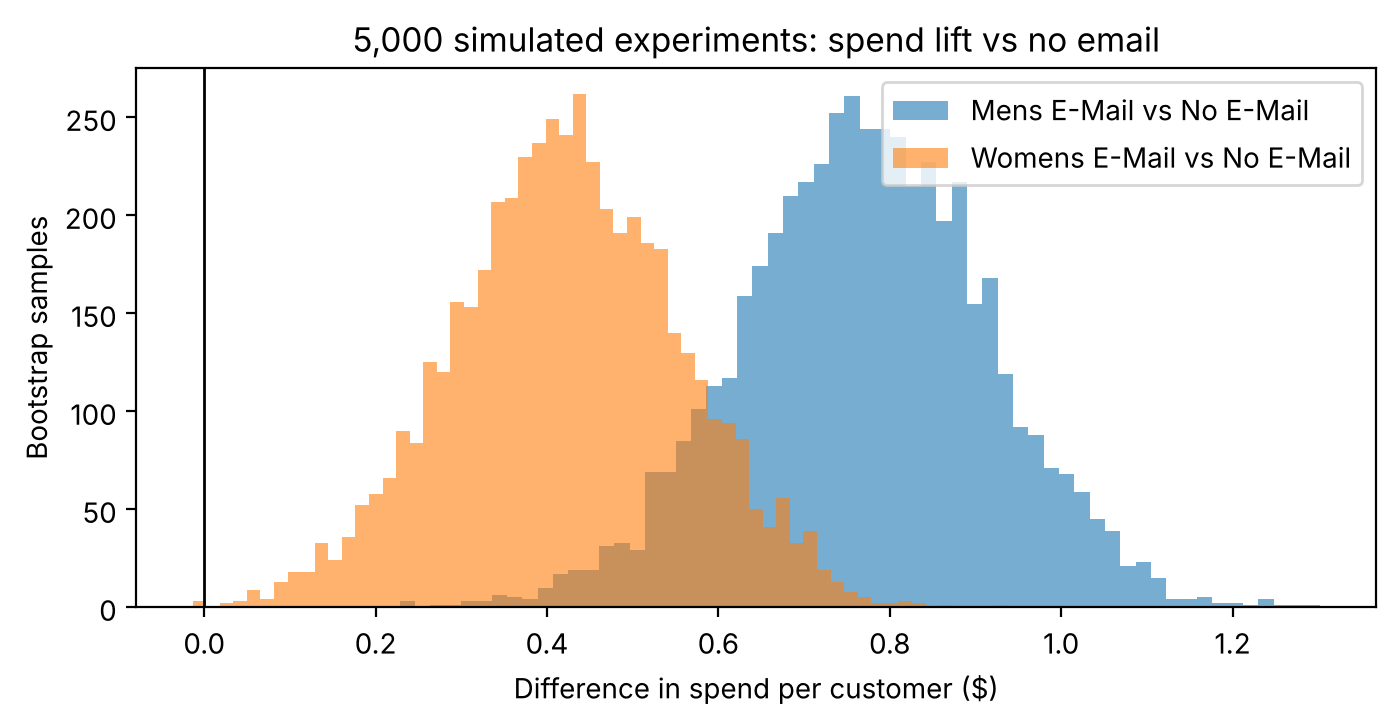

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for name in ["Mens E-Mail vs No E-Mail", "Womens E-Mail vs No E-Mail"]:
    ax.hist(boot_results[name], bins=60, alpha=0.6, label=name)
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Difference in spend per customer ($)")
ax.set_ylabel("Bootstrap samples")
ax.set_title("5,000 simulated experiments: spend lift vs no email")
ax.legend()
plt.show()

Each histogram shows the spread of 5,000 simulated spend lifts. Both lie almost entirely to the right of $0 (only a
handful of the women's-email simulations fall at or below $0), so both emails increase spend: about **+$0.77 per customer** for the men's email and **+$0.42** for the women's email.
The bootstrap and the Welch t-test agree here; with 21,000 customers per group the average is stable enough for
both methods. The men's vs women's difference is much less certain: its interval is wide and only just clears zero.

### 3.4 Where does the extra revenue come from?
Spend per customer = (share who buy) × (average order value of those who buy). The email could raise either one.

In [17]:
buyers = df[df["conversion"] == 1]
visitors = df[df["visit"] == 1]

funnel = pd.DataFrame({
    "visit_rate": df.groupby("segment")["visit"].mean(),
    "conversion_among_visitors": visitors.groupby("segment")["conversion"].mean(),
    "buyers": buyers.groupby("segment").size(),
    "avg_order_value_$": buyers.groupby("segment")["spend"].mean(),
})
funnel

,visit_rate,conversion_among_visitors,buyers,avg_order_value_$
segment,,,,
Mens E-Mail,0.1828,0.0686,267,113.5269
No E-Mail,0.1062,0.0539,122,114.0027
Womens E-Mail,0.1514,0.0584,189,121.8948


In [18]:
aov_tests = []
for treat in ["Mens E-Mail", "Womens E-Mail"]:
    a = buyers.loc[buyers["segment"] == treat, "spend"]
    b = buyers.loc[buyers["segment"] == "No E-Mail", "spend"]
    diffs = bootstrap_mean_diff(a, b)
    aov_tests.append({
        "comparison": f"{treat} vs No E-Mail",
        "aov_diff_$": a.mean() - b.mean(),
        "ci_low_$": np.percentile(diffs, 2.5),
        "ci_high_$": np.percentile(diffs, 97.5),
    })
pd.DataFrame(aov_tests)

,comparison,aov_diff_$,ci_low_$,ci_high_$
0,Mens E-Mail vs No E-Mail,-0.4758,-22.8347,21.6830
1,Womens E-Mail vs No E-Mail,7.8921,-15.4119,31.1823


The average order value is about the same in every group (around $114–122), and the confidence intervals for
the difference include $0. The emails do not make people spend more per order; they bring **more people** to the
site. For the men's email, a larger share of visitors also buy (6.9% vs 5.4%, p ≈ 0.02); for the women's email
that difference is not significant. The revenue gain is a volume effect.

### 3.5 Visual summary
Error bars show the 95% confidence interval of each group's value.

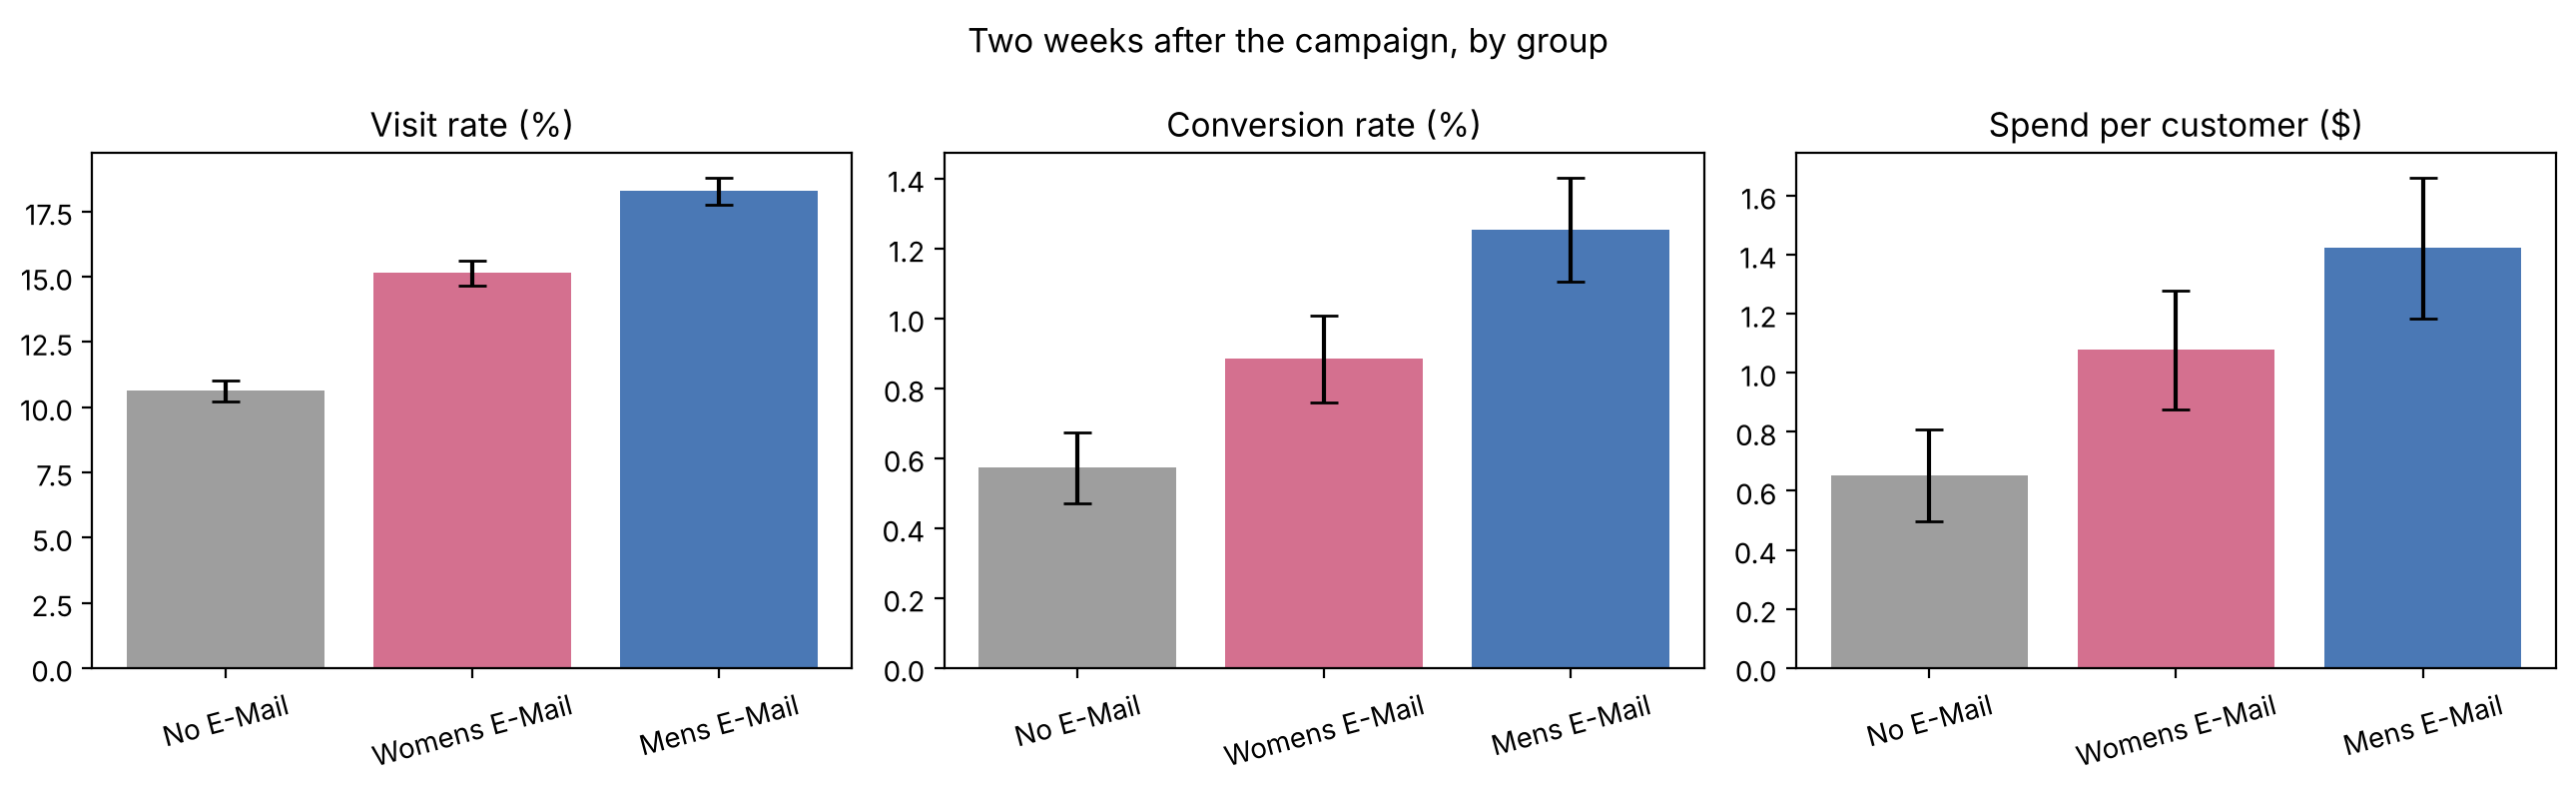

In [19]:
order = ["No E-Mail", "Womens E-Mail", "Mens E-Mail"]
colors = ["#9e9e9e", "#d4708f", "#4a78b5"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, metric, title, scale in zip(
    axes,
    ["visit", "conversion", "spend"],
    ["Visit rate (%)", "Conversion rate (%)", "Spend per customer ($)"],
    [100, 100, 1],
):
    g = df.groupby("segment")[metric]
    mean = g.mean().reindex(order) * scale
    ci = 1.96 * g.sem().reindex(order) * scale  # sem = standard error of the mean
    ax.bar(order, mean, yerr=ci, capsize=5, color=colors)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=15)

fig.suptitle("Two weeks after the campaign, by group")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "results_by_group.png", dpi=150)
plt.show()

### 3.6 What this means in business terms
Scaling the per-customer lift to a campaign of 100,000 customers:

In [20]:
campaign_size = 100_000
ctrl = df[df["segment"] == "No E-Mail"]

impact = pd.DataFrame({
    treat: {
        "extra_visits": (g["visit"].mean() - ctrl["visit"].mean()) * campaign_size,
        "extra_orders": (g["conversion"].mean() - ctrl["conversion"].mean()) * campaign_size,
        "extra_revenue_$": (g["spend"].mean() - ctrl["spend"].mean()) * campaign_size,
    }
    for treat, g in df.groupby("segment") if treat != "No E-Mail"
}).round(0)
impact

,Mens E-Mail,Womens E-Mail
extra_visits,7659.0000,4523.0000
extra_orders,681.0000,311.0000
extra_revenue_$,76983.0000,42441.0000


**Section 3 conclusion:** both emails work. Sending the men's email to 100,000 customers brings roughly 7,700
extra visits, 680 extra orders and $77,000 extra revenue over two weeks, compared with sending nothing. The
women's email delivers roughly half of that (59% of the extra visits, 46% of the orders, 55% of the revenue). The gain comes from more buyers, not bigger orders.

The obvious next question: is the men's email better *for everyone*, or only for some customers?

## 4. Who responds to which email?

The overall lift is an average. It can hide groups where an email works very well and groups where it does
nothing. Here the lift is broken down by customer characteristics.

**Choices made:**
- **Main metric: visit rate.** Only about 580 customers bought anything, so per-subgroup conversion counts
  get very small (in some cells fewer than 20, and as few as 3). Visits have about 16 times more positives, giving reliable
  subgroup estimates. Conversion and spend are checked afterwards for the key finding.
- **SQL with DuckDB.** DuckDB runs SQL directly on the pandas DataFrame in memory, without setting up a database.
- **Multiple comparisons.** Testing many subgroups means some will look significant by luck. A Bonferroni
  correction is applied: the significance threshold is 0.05 divided by the number of tests.

### 4.1 Subgroup counts with SQL
The query below:
1. `base` creates two new grouping columns with `CASE WHEN`: **buyer type** (bought men's only, women's only,
   or both in the past year) and **recency band** (months since last purchase, in groups of 3).
2. `long` stacks every grouping dimension into one long table with `UNION ALL`, so the next step can count
   everything in one go.
3. The final `SELECT` counts customers, visits and conversions for every subgroup × email group.

In [21]:
subgroup_counts = duckdb.sql('''
    WITH base AS (
        SELECT
            *,
            CASE
                WHEN mens = 1 AND womens = 1 THEN 'both'
                WHEN mens = 1 THEN 'mens only'
                ELSE 'womens only'
            END AS buyer_type,
            CASE
                WHEN recency <= 3 THEN '01-03 months'
                WHEN recency <= 6 THEN '04-06 months'
                WHEN recency <= 9 THEN '07-09 months'
                ELSE '10-12 months'
            END AS recency_band
        FROM df
    ),
    long AS (
        SELECT 'buyer_type' AS dimension, buyer_type AS subgroup, segment, visit, conversion FROM base
        UNION ALL
        SELECT 'customer', CASE WHEN newbie = 1 THEN 'new' ELSE 'existing' END, segment, visit, conversion FROM base
        UNION ALL
        SELECT 'channel', channel, segment, visit, conversion FROM base
        UNION ALL
        SELECT 'zip_code', zip_code, segment, visit, conversion FROM base
        UNION ALL
        SELECT 'recency', recency_band, segment, visit, conversion FROM base
        UNION ALL
        SELECT 'history', history_segment, segment, visit, conversion FROM base
    )
    SELECT
        dimension,
        subgroup,
        segment,
        COUNT(*)        AS customers,
        SUM(visit)      AS visits,
        SUM(conversion) AS conversions
    FROM long
    GROUP BY dimension, subgroup, segment
    ORDER BY dimension, subgroup, segment
''').df()

subgroup_counts.head(9)

,dimension,subgroup,segment,customers,visits,conversions
0,buyer_type,both,Mens E-Mail,2181,687.0000,53.0000
1,buyer_type,both,No E-Mail,2149,388.0000,20.0000
2,buyer_type,both,Womens E-Mail,2118,533.0000,31.0000
3,buyer_type,mens only,Mens E-Mail,9558,1615.0000,110.0000
4,buyer_type,mens only,No E-Mail,9638,962.0000,53.0000
5,buyer_type,mens only,Womens E-Mail,9622,1067.0000,59.0000
6,buyer_type,womens only,Mens E-Mail,9568,1592.0000,104.0000
7,buyer_type,womens only,No E-Mail,9519,912.0000,49.0000
8,buyer_type,womens only,Womens E-Mail,9647,1638.0000,99.0000


### 4.2 Lift per subgroup
For each subgroup, each email is compared with No E-Mail using the same `two_prop_test` function as in
section 3, now fed with subgroup counts.

In [22]:
counts = subgroup_counts.set_index(["dimension", "subgroup", "segment"]).unstack("segment")

lift_rows = []
for (dimension, subgroup), r in counts.iterrows():
    for treat in ["Mens E-Mail", "Womens E-Mail"]:
        res = two_prop_test(
            r[("visits", treat)], r[("customers", treat)],
            r[("visits", "No E-Mail")], r[("customers", "No E-Mail")],
        )
        lift_rows.append({"dimension": dimension, "subgroup": subgroup, "email": treat,
                          "customers": int(r["customers"].sum()), **res})

subgroup_lift = pd.DataFrame(lift_rows)

n_tests = len(subgroup_lift)
alpha_adjusted = 0.05 / n_tests
subgroup_lift["significant_bonferroni"] = subgroup_lift["p_value"] < alpha_adjusted
print(f"{n_tests} tests -> Bonferroni threshold p < {alpha_adjusted:.5f}")

subgroup_lift.pivot_table(
    index=["dimension", "subgroup"], columns="email",
    values=["lift_pts", "significant_bonferroni"], aggfunc="first",
)

44 tests -> Bonferroni threshold p < 0.00114


lift_pts               significant_bonferroni  \
email                       Mens E-Mail Womens E-Mail            Mens E-Mail   
dimension  subgroup                                                            
buyer_type both                 13.4444        7.1103                   True   
           mens only             6.9155        1.1078                   True   
           womens only           7.0580        7.3985                   True   
channel    Multichannel          8.2937        4.7100                   True   
           Phone                 7.5604        4.4630                   True   
           Web                   7.5563        4.5677                   True   
customer   existing              7.7833        4.0123                   True   
           new                   7.5305        5.0417                   True   
history    1) $0 - $100          6.8552        4.6782                   True   
           2) $100 - $200        6.9110        4.2504                   True   
           3) $200 - $350        8.4398        3.6095                   True   
           4) $350 - $500        8.9201        4.0397                   True   
           5) $500 - $750        9.8952        6.6128                   True   
           6) $750 - $1,000      6.1498        5.4765                  False   
           7) $1,000 +           9.7066        5.3761                   True   
recency    01-03 months          8.4982        4.4000                   True   
           04-06 months          7.5505        4.0474                   True   
           07-09 months          7.0371        5.3793                   True   
           10-12 months          7.0393        4.3502                   True   
zip_code   Rural                 7.3398        2.9095                   True   
           Suburban              7.4337        4.8863                   True   
           Urban                 7.9641        4.6943                   True   

                                           
email                       Womens E-Mail  
dimension  subgroup                        
buyer_type both                      True  
           mens only                False  
           womens only               True  
channel    Multichannel              True  
           Phone                     True  
           Web                       True  
customer   existing                  True  
           new                       True  
history    1) $0 - $100              True  
           2) $100 - $200            True  
           3) $200 - $350            True  
           4) $350 - $500            True  
           5) $500 - $750            True  
           6) $750 - $1,000         False  
           7) $1,000 +              False  
recency    01-03 months              True  
           04-06 months              True  
           07-09 months              True  
           10-12 months              True  
zip_code   Rural                    False  
           Suburban                  True  
           Urban                     True

### 4.3 Forest plot
Each row is a subgroup. The dot is the visit lift in percentage points, the line is its 95% confidence interval,
and the vertical line at 0 means "no effect". Rows where the two colors are far apart are where the choice
of email matters.

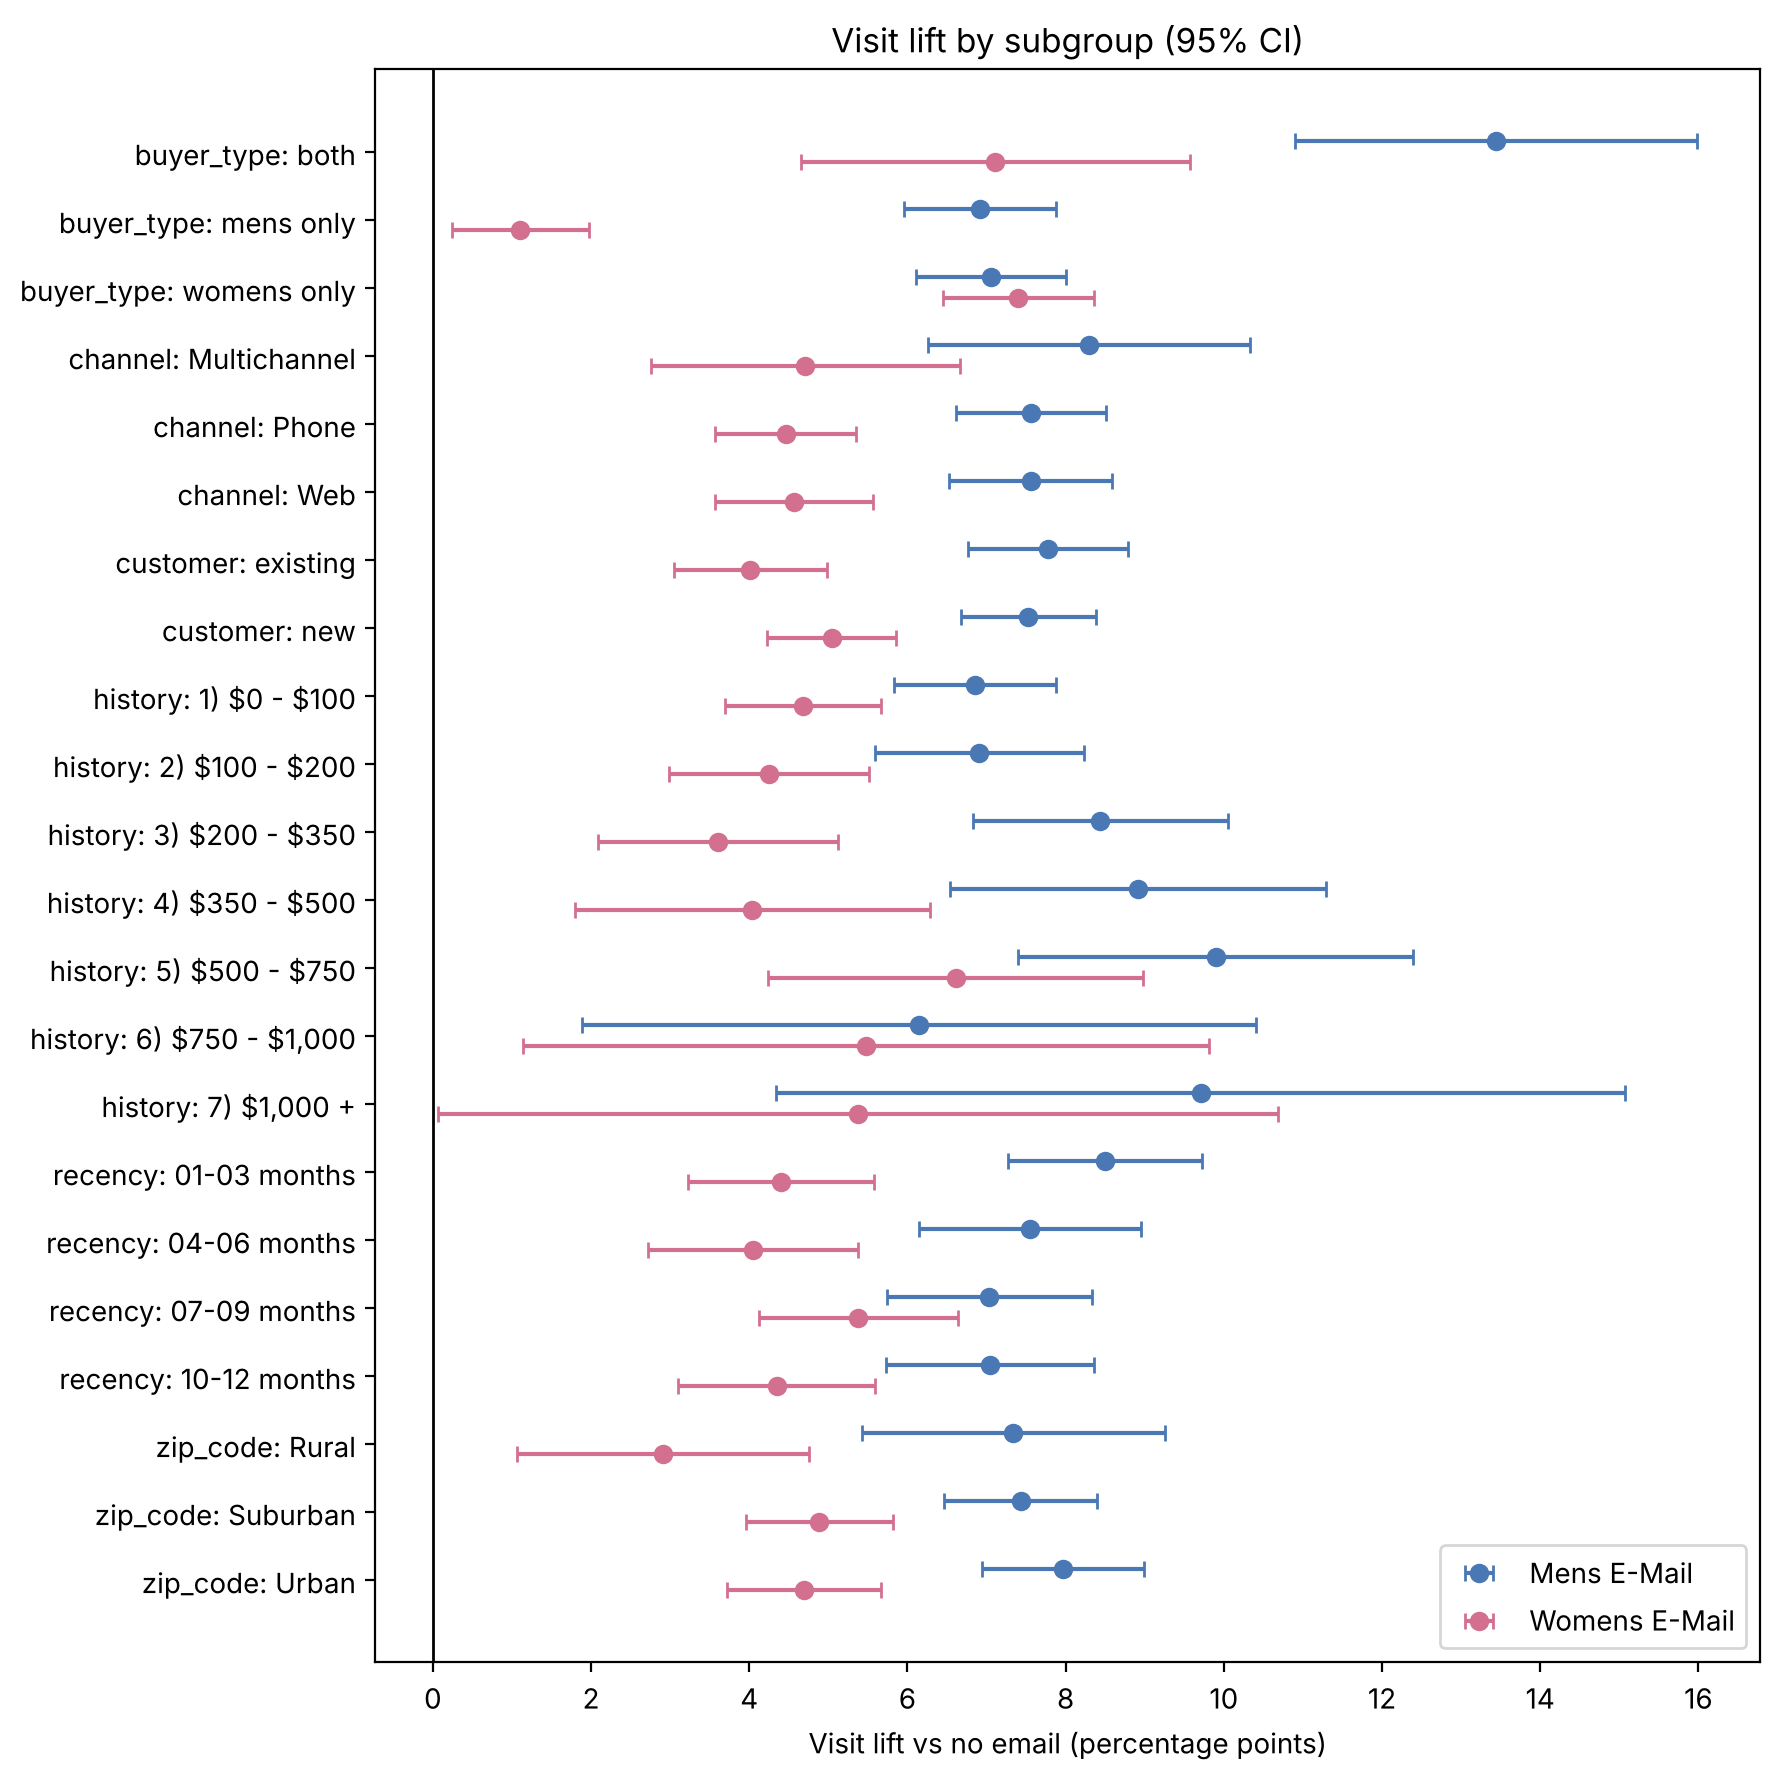

In [23]:
plot_df = subgroup_lift.copy()
plot_df["label"] = (plot_df["dimension"] + ": " + plot_df["subgroup"]).str.replace("$", r"\$", regex=False)  # "$" would trigger math mode
labels = plot_df["label"].drop_duplicates().tolist()
y_pos = {label: i for i, label in enumerate(reversed(labels))}

fig, ax = plt.subplots(figsize=(9, 9))
for email, color, offset in [("Mens E-Mail", "#4a78b5", 0.15), ("Womens E-Mail", "#d4708f", -0.15)]:
    sub = plot_df[plot_df["email"] == email]
    y = sub["label"].map(y_pos) + offset
    ax.errorbar(
        sub["lift_pts"], y,
        xerr=[sub["lift_pts"] - sub["ci_low_pts"], sub["ci_high_pts"] - sub["lift_pts"]],
        fmt="o", color=color, label=email, capsize=3,
    )

ax.axvline(0, color="black", linewidth=1)
ax.set_yticks(list(y_pos.values()))
ax.set_yticklabels(list(y_pos.keys()))
ax.set_xlabel("Visit lift vs no email (percentage points)")
ax.set_title("Visit lift by subgroup (95% CI)")
ax.legend(loc="lower right")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "subgroup_forest_plot.png", dpi=150)
plt.show()

**What the plot shows**
- **Most dimensions do not change the picture.** Across region, channel, recency, spend history and new vs
  existing customers, both emails work and the men's email is ahead by a similar margin. (The two highest
  spend-history buckets have wide intervals simply because they contain few customers.)
- **Buyer type is the exception.** For customers who bought only **men's** items, the women's email barely
  works (about +1 pt), while the men's email gives about +7 pts. For customers who bought only **women's** items,
  the two emails perform about the same (about +7 pts each).

In other words: the men's email works for everyone, while the women's email works mainly on people who already
buy women's products. (For men's-only buyers its +1.1 pt lift is significant at the usual 5% level, but not after
the Bonferroni correction.) The subgroup tests are about visits, so the next step checks whether conversion and spend
show the same pattern.

### 4.4 Buyer type: all three outcomes

In [24]:
df["buyer_type"] = np.select(
    [(df["mens"] == 1) & (df["womens"] == 1), df["mens"] == 1],
    ["both", "mens only"],
    default="womens only",
)

buyer_table = df.pivot_table(
    index="buyer_type", columns="segment",
    values=["visit", "conversion", "spend"], aggfunc="mean",
)[["visit", "conversion", "spend"]]
buyer_table["customers", "all"] = df.groupby("buyer_type").size()
buyer_table

visit                          conversion            \
segment     Mens E-Mail No E-Mail Womens E-Mail Mens E-Mail No E-Mail   
buyer_type                                                              
both             0.3150    0.1805        0.2517      0.0243    0.0093   
mens only        0.1690    0.0998        0.1109      0.0115    0.0055   
womens only      0.1664    0.0958        0.1698      0.0109    0.0051   

                                spend                         customers  
segment     Womens E-Mail Mens E-Mail No E-Mail Womens E-Mail       all  
buyer_type                                                               
both               0.0146      3.0051    1.1801        1.3420      6448  
mens only          0.0061      1.3782    0.6954        0.9738     28818  
womens only        0.0103      1.1063    0.4906        1.1222     28734

Conversion and spend follow the same pattern as visits:
- **Men's-only buyers** (about 29k customers): the men's email doubles conversion; the women's email adds little.
- **Women's-only buyers** (about 29k): both emails perform similarly, with no clear winner.
- **Both** (about 6k): the men's email is ahead.

Because buyers per cell are small here (from 20 to about 110), conversion and spend differences between the two emails
for women's-only buyers should be read as "about equal", not as a winner.

## 5. Recommendation: who should get which email?

Because customers were assigned at random, each group's results show what *would* happen if a strategy were
applied to everyone. So a targeting strategy can be evaluated directly on the data: for each buyer type, take the
observed results of the email the strategy assigns to it, and weight by how many customers are in that buyer type.

| Strategy | Who gets what |
|---|---|
| No email | Nobody |
| Women's email to all | Everyone gets the women's email |
| Men's email to all | Everyone gets the men's email |
| **Targeted** | Women's-only buyers get the women's email; everyone else gets the men's email |

In [25]:
strategies = {
    "No email":             {"both": "No E-Mail",   "mens only": "No E-Mail",   "womens only": "No E-Mail"},
    "Women's email to all": {"both": "Womens E-Mail", "mens only": "Womens E-Mail", "womens only": "Womens E-Mail"},
    "Men's email to all":   {"both": "Mens E-Mail", "mens only": "Mens E-Mail", "womens only": "Mens E-Mail"},
    "Targeted":             {"both": "Mens E-Mail", "mens only": "Mens E-Mail", "womens only": "Womens E-Mail"},
}

cell_means = df.groupby(["buyer_type", "segment"])[["visit", "conversion", "spend"]].mean()
share = df["buyer_type"].value_counts(normalize=True)

strategy_results = pd.DataFrame({
    name: sum(cell_means.loc[(bt, email)] * share[bt] for bt, email in plan.items())
    for name, plan in strategies.items()
}).T
strategy_results.columns = ["visit_rate", "conversion_rate", "spend_per_customer_$"]
strategy_results

,visit_rate,conversion_rate,spend_per_customer_$
No email,0.1061,0.0057,0.6523
Women's email to all,0.1515,0.0088,1.0775
Men's email to all,0.1825,0.0125,1.4200
Targeted,0.1841,0.0122,1.4272


**Recommendation**
1. **Keep emailing.** Both emails clearly outperform sending nothing on visits, conversions and revenue.
2. **Default to the men's email.** It performs best overall and works for every customer type.
3. **Optionally, send the women's email to customers who buy women's products exclusively.** For them it performs
   about as well as the men's email. The targeted strategy ends up roughly equal to "men's email to all" (slightly
   more visits and spend, slightly fewer orders, all well within noise). So the choice is not about revenue: it
   lets the business keep sending women's-product messaging to the customers it is relevant to, with no
   measurable loss. What the data clearly rules out is sending the women's email to **men's-only buyers**, where it
   barely works.

**Limitations**
- **Two-week window.** Long-term effects (repeat purchases, unsubscribes, email fatigue) are not measured.
- **No cost data.** Emails are cheap, but unsubscribe rates and margins would change the business case.
- **Spend is noisy.** With about 580 buyers in total, spend and conversion differences between the two emails
  within a subgroup are not precise.
- **The targeted strategy was chosen from this same data**, so its result is slightly optimistic. It should be
  confirmed with a new test before being rolled out.
- **Data from 2008.** Customer behavior and email channels have changed since.

A follow-up notebook (`uplift_modeling.ipynb`) tests whether a machine-learning model can find better targeting
than this simple rule.